In [1]:
pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


# Online Shopper Purchase Intention Prediction

## Exploratory Data Analysis (EDA)

**Research Objective:**  
To investigate online shopping session behavior and identify patterns
associated with purchase decisions.

**Dataset:** Online Shoppers Purchasing Intention Dataset

**Source:** UCI Machine Learning Repository

**Research Type:** Supervised Machine Learning - Binary Classification

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Fetch dataset from UCI
dataset = fetch_ucirepo(id=468)

# Separate features and target
X = dataset.data.features
y = dataset.data.targets

# Combine into one DataFrame
df = pd.concat([X, y], axis=1)

print("Dataset loaded successfully!")
print("Dataset dimensions:", df.shape)

df.head()

Dataset loaded successfully!
Dataset dimensions: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [5]:
# Display column names
print("Dataset columns:")
print(df.columns.tolist())

# Display dataset information
df.info()

Dataset columns:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']
<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64

In [6]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate records:", df.duplicated().sum())

# Check target distribution
print("\nPurchase distribution:")
print(df["Revenue"].value_counts())

# Check target percentages
print("\nPurchase percentages:")
print(df["Revenue"].value_counts(normalize=True) * 100)

Missing values:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

Duplicate records: 125

Purchase distribution:
Revenue
False    10422
True      1908
Name: count, dtype: int64

Purchase percentages:
Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64


## Initial Exploratory Data Analysis Findings

The dataset contains 12,330 online shopping sessions and 18
columns, including 17 predictor variables and one target variable
called Revenue.

The initial data inspection identified no missing values.

The target variable is imbalanced. Approximately 84.53% of
sessions did not result in a purchase, while 15.47% resulted
in a purchase.

This imbalance makes accuracy alone an insufficient evaluation
metric. Therefore, the research will emphasize precision,
recall, F1-score, and Precision-Recall AUC.

The initial inspection also identified 125 duplicate records.
These records will be investigated before making data-cleaning
decisions.

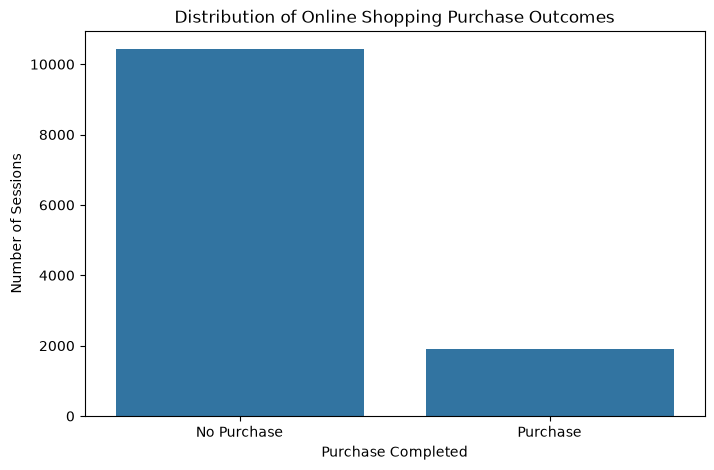

In [7]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Revenue")

plt.title("Distribution of Online Shopping Purchase Outcomes")
plt.xlabel("Purchase Completed")
plt.ylabel("Number of Sessions")

plt.xticks([0, 1], ["No Purchase", "Purchase"])

plt.show()

In [8]:
# Identify duplicate records
duplicates = df[df.duplicated(keep=False)]

print("Total rows involved in duplicates:", len(duplicates))

print("\nRevenue distribution among duplicate rows:")
print(duplicates["Revenue"].value_counts())

print("\nSample duplicate records:")
display(duplicates.head(10))

Total rows involved in duplicates: 201

Revenue distribution among duplicate rows:
Revenue
False    201
Name: count, dtype: int64

Sample duplicate records:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
85,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
132,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
252,0,0.0,0,0.0,2,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,False,False
286,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,1,1,Returning_Visitor,False,False
293,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,True,False
298,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,8,1,Returning_Visitor,False,False
330,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,3,2,3,1,Returning_Visitor,False,False


## Feature Analysis

This section investigates the relationship between visitor
behavior and purchase outcomes.

The analysis focuses on product browsing activity, page values,
exit rates, bounce rates, and visitor types.

The objective is to identify behavioral differences between
shopping sessions that resulted in purchases and those that
did not.

In [10]:
numerical_features = [
    "Administrative",
    "Informational",
    "ProductRelated",
    "Administrative_Duration",
    "Informational_Duration",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues"
]

comparison = df.groupby("Revenue")[numerical_features].median().T

comparison.columns = ["No Purchase", "Purchase"]

display(comparison.round(3))

,No Purchase,Purchase
Administrative,0.000,2.000
Informational,0.000,0.000
ProductRelated,16.000,29.000
Administrative_Duration,0.000,52.367
Informational_Duration,0.000,0.000
ProductRelated_Duration,510.190,1109.906
BounceRates,0.004,0.000
ExitRates,0.029,0.016
PageValues,0.000,16.758


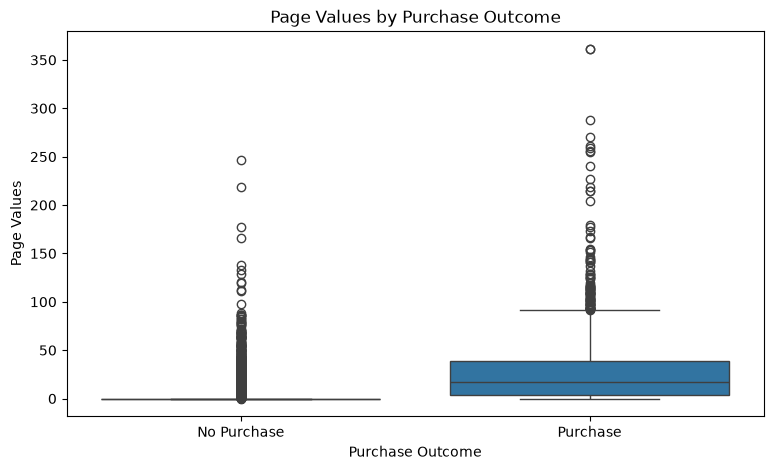

In [11]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Revenue",
    y="PageValues"
)

plt.title("Page Values by Purchase Outcome")
plt.xlabel("Purchase Outcome")
plt.ylabel("Page Values")

plt.xticks([0, 1], ["No Purchase", "Purchase"])

plt.show()

In [12]:
visitor_analysis = pd.crosstab(
    df["VisitorType"],
    df["Revenue"],
    normalize="index"
) * 100

display(visitor_analysis.round(2))

Revenue,False,True
VisitorType,,
New_Visitor,75.09,24.91
Other,81.18,18.82
Returning_Visitor,86.07,13.93
